# C5 — LightGBM Optuna Tuning & Training

This is **C5**, not C6.

Primary tuning metric: **PR-AUC**.

Secondary metrics:
- ROC-AUC
- Log Loss
- Brier Score

Evaluation protocol:
- C4 splits remain fixed.
- Optuna sees only C4 TRAIN.
- 5-fold StratifiedGroupKFold grouped by `case_id`.
- Validation is used after tuning.
- Test is untouched until final evaluation.
- Identifiers and `logging_policy` are excluded from predictive X.
- `action_type` and `channel` remain intervention variables.

In [1]:

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if not (ROOT / "data" / "c4_splits").exists():
    ROOT = ROOT.parent

SPLIT_DIR = ROOT / "data" / "c4_splits"
REPORT_DIR = ROOT / "reports" / "c5_tuned_models"
MODEL_DIR = ROOT / "models" / "c5"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

SEED = 20260824
TARGET = "y"
GROUP_COL = "case_id"
N_SPLITS = 5
N_TRIALS = 30

train = pd.read_csv(SPLIT_DIR / "train.csv", low_memory=False)
valid = pd.read_csv(SPLIT_DIR / "validation.csv", low_memory=False)
test = pd.read_csv(SPLIT_DIR / "test.csv", low_memory=False)

assert TARGET in train.columns
assert GROUP_COL in train.columns

print("Train:", train.shape)
print("Validation:", valid.shape)
print("Test:", test.shape)
print("Train positive rate:", train[TARGET].mean())


Train: (110385, 37)
Validation: (23471, 37)
Test: (23567, 37)
Train positive rate: 0.2282194138696381


## 1. Feature Contract

In [2]:

ID_COLUMNS = {"customer_id", "subscription_id", "case_id"}
POLICY_COLUMNS = {"logging_policy"}
INTERVENTION_COLUMNS = {"action_type", "channel"}

EXCLUDED = ID_COLUMNS | POLICY_COLUMNS | {TARGET}
FEATURES = [c for c in train.columns if c not in EXCLUDED]

CATEGORICAL_COLS = [
    c for c in FEATURES
    if c in INTERVENTION_COLUMNS
    or not pd.api.types.is_numeric_dtype(train[c])
]

NUMERIC_COLS = [
    c for c in FEATURES
    if c not in CATEGORICAL_COLS
    and pd.api.types.is_numeric_dtype(train[c])
]

print("Numeric features:", len(NUMERIC_COLS))
print("Categorical features:", len(CATEGORICAL_COLS))
print("Intervention variables:",
      [c for c in INTERVENTION_COLUMNS if c in train.columns])


Numeric features: 20
Categorical features: 12
Intervention variables: ['action_type', 'channel']


## 2. Preprocessing

In [3]:

def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=2)),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, NUMERIC_COLS),
        ("categorical", categorical_pipe, CATEGORICAL_COLS),
    ])


## 3. Metrics

In [4]:

def evaluate(y_true, proba):
    proba = np.clip(np.asarray(proba, dtype=float), 1e-7, 1 - 1e-7)
    y_true = np.asarray(y_true)
    return {
        "pr_auc": float(average_precision_score(y_true, proba)),
        "roc_auc": float(roc_auc_score(y_true, proba)),
        "log_loss": float(log_loss(y_true, proba)),
        "brier": float(brier_score_loss(y_true, proba)),
    }


## 4. Optuna Search Space

In [5]:

import optuna
from lightgbm import LGBMClassifier

def lgb_params(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1200, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 200),
        "max_depth": trial.suggest_int("max_depth", 3, 14),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 250, step=10),
        "subsample": trial.suggest_float("subsample", 0.60, 1.00),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.60, 1.00),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 30.0, log=True),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 5.0),
    }


## 5. Optuna Objective — TRAIN ONLY

In [6]:

import optuna

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED,
)

X_train = train[FEATURES]
y_train = train[TARGET].astype(int)
groups = train[GROUP_COL]

def lgb_objective(trial):
    params = lgb_params(trial)
    fold_scores = []

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train, groups)):
        X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

        prep = make_preprocessor()
        X_tr_enc = prep.fit_transform(X_tr)
        X_va_enc = prep.transform(X_va)

        model = LGBMClassifier(
            **params,
            objective="binary",
            random_state=SEED + fold,
            n_jobs=-1,
            verbosity=-1,
        )
        model.fit(X_tr_enc, y_tr)
        proba = model.predict_proba(X_va_enc)[:, 1]
        score = average_precision_score(y_va, proba)
        fold_scores.append(score)

        trial.report(float(np.mean(fold_scores)), step=fold)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("cv_pr_auc_std", float(np.std(fold_scores)))
    return float(np.mean(fold_scores))


## 6. Run Optuna

In [7]:

optuna.logging.set_verbosity(optuna.logging.WARNING)

lgb_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED + 1),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=2,
    ),
)

lgb_study.optimize(
    lgb_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True,
)

print("Best CV PR-AUC:", lgb_study.best_value)
print("Best parameters:")
print(lgb_study.best_params)


  0%|          | 0/30 [00:00<?, ?it/s]

Best CV PR-AUC: 0.8106829383903269
Best parameters:
{'n_estimators': 900, 'learning_rate': 0.012037534309489825, 'num_leaves': 113, 'max_depth': 13, 'min_child_samples': 30, 'subsample': 0.703308220016202, 'colsample_bytree': 0.7833760595417959, 'reg_alpha': 0.021617448517414702, 'reg_lambda': 1.080172204110612, 'min_split_gain': 0.4243373959249762}


## 7. Trial Analysis

,number,value,state
27,27,0.810683,COMPLETE
17,17,0.810496,COMPLETE
26,26,0.810346,COMPLETE
28,28,0.809472,COMPLETE
25,25,0.808960,COMPLETE
29,29,0.808817,COMPLETE
18,18,0.808686,COMPLETE
21,21,0.808320,COMPLETE
22,22,0.808315,COMPLETE
4,4,0.808022,COMPLETE


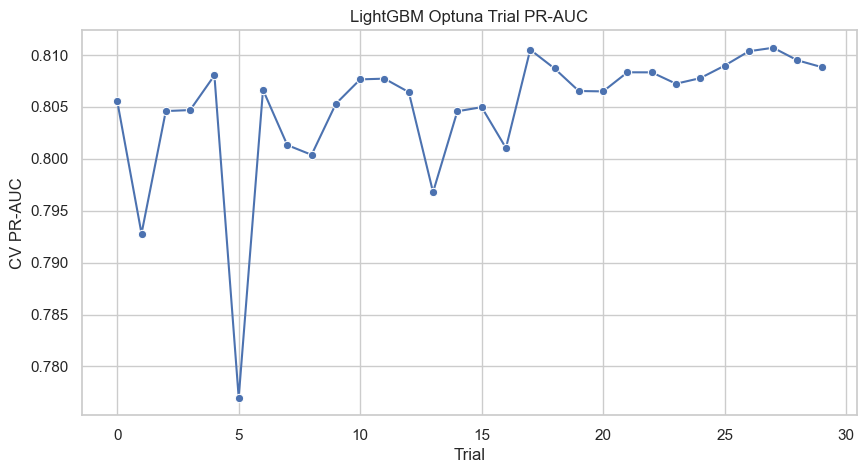

In [9]:

trials = lgb_study.trials_dataframe()
display(
    trials[["number","value","state"]]
    .sort_values("value", ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
sns.lineplot(
    data=trials.sort_values("number"),
    x="number",
    y="value",
    marker="o",
)
plt.title("LightGBM Optuna Trial PR-AUC")
plt.xlabel("Trial")
plt.ylabel("CV PR-AUC")
plt.show()


## 8. Fit Best Configuration on Complete C4 TRAIN

In [ ]:
# ============================================================
# FIT BEST LIGHTGBM — FINAL TRAINING AFTER OPTUNA
# ============================================================

from lightgbm import LGBMClassifier

best_lgb = LGBMClassifier(
    **lgb_study.best_params,
    objective="binary",
    random_state=SEED,
    n_jobs=-1,
    verbosity=-1,
    force_col_wise=True,
)

print("Encoding training data...")

final_prep = make_preprocessor()

Xtr = final_prep.fit_transform(
    train[FEATURES]
)

Xva = final_prep.transform(
    valid[FEATURES]
)

Xte = final_prep.transform(
    test[FEATURES]
)

print("Encoded shapes:")
print("Train:", Xtr.shape)
print("Validation:", Xva.shape)
print("Test:", Xte.shape)

print("\nStarting LightGBM final training...")
print("Best parameters:")
print(lgb_study.best_params)

best_lgb.fit(
    Xtr,
    train[TARGET].astype(int),
)

print("Training finished.")

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

train_proba = best_lgb.predict_proba(
    Xtr
)[:, 1]

valid_proba = best_lgb.predict_proba(
    Xva
)[:, 1]

test_proba = best_lgb.predict_proba(
    Xte
)[:, 1]

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

lgb_results = pd.DataFrame([
    {
        "split": "train",
        **evaluate(
            train[TARGET],
            train_proba
        ),
    },
    {
        "split": "validation",
        **evaluate(
            valid[TARGET],
            valid_proba
        ),
    },
    {
        "split": "test",
        **evaluate(
            test[TARGET],
            test_proba
        ),
    },
])

display(lgb_results)

Encoding training data...
Encoded shapes:
Train: (110385, 79)
Validation: (23471, 79)
Test: (23567, 79)

Starting LightGBM training...
Best parameters:
{'n_estimators': 900, 'learning_rate': 0.012037534309489825, 'num_leaves': 113, 'max_depth': 13, 'min_child_samples': 30, 'subsample': 0.703308220016202, 'colsample_bytree': 0.7833760595417959, 'reg_alpha': 0.021617448517414702, 'reg_lambda': 1.080172204110612, 'min_split_gain': 0.4243373959249762}
Training finished.


,split,pr_auc,roc_auc,log_loss,brier
0,train,0.903897,0.966646,0.208394,0.062760
1,validation,0.813796,0.934843,0.264603,0.082901
2,test,0.828669,0.938508,0.255014,0.078848


## 9. Compare Against Existing C5 Baselines

In [13]:

baseline_path = ROOT / "reports" / "c5_baseline" / "baseline_metrics.csv"
if baseline_path.exists():
    baseline = pd.read_csv(baseline_path)
    compare = pd.concat([
        baseline.assign(source="C5_fixed_baseline"),
        model_results.assign(model="lightgbm_tuned", source="C5_tuned"),
    ], ignore_index=True)
    display(compare[["model","split","pr_auc","roc_auc","log_loss","brier"]]
            .sort_values(["split","pr_auc"], ascending=[True,False]))
else:
    print("C5 baseline metrics not found.")


NameError: name 'model_results' is not defined

## 10. Save Results and Model

In [12]:

import joblib

model_results.to_csv(
    REPORT_DIR / "lightgbm_metrics.csv",
    index=False,
)

lgb_study.trials_dataframe().to_csv(
    REPORT_DIR / "lightgbm_optuna_trials.csv",
    index=False,
)

with open(
    REPORT_DIR / "lightgbm_best_params.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "optimization_metric": "pr_auc",
            "cv": "5-fold StratifiedGroupKFold",
            "group": GROUP_COL,
            "best_cv_pr_auc": lgb_study.best_value,
            "best_params": lightgbm_study.best_params,
        },
        f,
        indent=2,
    )

joblib.dump(
    Pipeline([
        ("preprocess", final_prep),
        ("model", best_lgb),
    ]),
    MODEL_DIR / "lightgbm_tuned_c5.joblib",
)

print("Saved LightGBM C5 artifacts.")


NameError: name 'model_results' is not defined

## Model-selection rule

**Primary:** CV PR-AUC, then validation PR-AUC.

**Secondary:** ROC-AUC, Log Loss, Brier.

The test set is a final report only. Do not go back to Optuna after looking at
test results, because that would turn the test set into a tuning signal.